# From NumPy arrays to a first model: k-Nearest Neighbors from scratch

Goals of this notebook:

1. move from Python lists to NumPy arrays: shape, axes, vectorized operations, boolean masks, broadcasting;
2. write a k-Nearest Neighbors (kNN) classifier from scratch, using NumPy only;
3. learn to evaluate it honestly: training set, validation set, test set, overfitting and underfitting;
4. apply it to a real problem, handwritten digit recognition, and compare it with scikit-learn.

How to read this notebook: every function of the algorithm is followed by a cell of `assert` checks that verify it on small, hand-computed cases. Run the cells in order, because each section reuses the functions of the previous ones.

## Setup

Run the next cell once at the start. Only NumPy, matplotlib and, for the datasets and the final comparison, scikit-learn are needed: on Google Colab they are already installed.

In [1]:
import sys
import time

import numpy as np
import matplotlib.pyplot as plt

# Plot colors and style: blue for the first class, orange for the second, near-black for the query
C_A, C_B, C_Q = "#2a78d6", "#eb6834", "#1a1a19"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8a8a",
    "font.size": 10, "legend.frameon": False,
})
print("NumPy", np.__version__)

NumPy 2.5.3


# Part A – NumPy

## 1. Why lists are not enough

Lists are Python's everyday tool, but they were not built for numerical computing. Two experiments show it right away.

First: arithmetic. On lists, `+` and `*` do not compute, they concatenate and repeat.

In [2]:
lst = [1, 2, 3]
print("lst + lst:", lst + lst)      # concatenates
print("lst * 2:  ", lst * 2)        # repeats

arr = np.array([1, 2, 3])           # a NumPy array is built from a list
print("arr + arr:", arr + arr)      # element-wise sum
print("arr * 2:  ", arr * 2)        # multiplies every element

lst + lst: [1, 2, 3, 1, 2, 3]
lst * 2:   [1, 2, 3, 1, 2, 3]
arr + arr: [2 4 6]
arr * 2:   [2 4 6]


Second: time and memory. Let's add up one million integers with a Python loop and with NumPy, and measure how much space they take.

`benchmark` is a small helper used throughout the notebook. It takes a function and its arguments, calls it a few times and returns the best time in milliseconds. The `*args` parameter collects any number of positional arguments into a tuple, and `func(*args)` unpacks them again: this is what lets the same helper time functions that take one, two or four arguments. The minimum, rather than the mean, is reported because timings are pushed upwards by unrelated events (the operating system, the garbage collector, a cold cache): the lowest time is the most faithful estimate of the real cost.

In [3]:
def benchmark(func, *args, repetitions=5):
    # Returns the best time over a few repetitions, in milliseconds
    best = float("inf")
    for _ in range(repetitions):
        start = time.perf_counter()
        func(*args)
        best = min(best, time.perf_counter() - start)
    return best * 1000


def sum_with_loop(values):
    total = 0
    for v in values:
        total += v
    return total


n = 1_000_000
lst = list(range(n))
arr = np.arange(n)            # like range, but returns an array

t_loop = benchmark(sum_with_loop, lst)
t_np = benchmark(np.sum, arr)
print(f"Sum of {n:,} elements")
print(f"  for loop over a list: {t_loop:8.2f} ms")
print(f"  np.sum over an array: {t_np:8.2f} ms   -> {t_loop / t_np:.0f}x faster")

bytes_list = sys.getsizeof(lst) + sum(sys.getsizeof(x) for x in lst)
print(f"\nMemory for {n:,} integers")
print(f"  list:  {bytes_list / 1e6:6.1f} MB   (pointers + one Python object per number)")
print(f"  array: {arr.nbytes / 1e6:6.1f} MB   (just the numbers, {arr.dtype})")

Sum of 1,000,000 elements
  for loop over a list:    20.30 ms
  np.sum over an array:     0.26 ms   -> 80x faster



Memory for 1,000,000 integers
  list:    36.0 MB   (pointers + one Python object per number)
  array:    8.0 MB   (just the numbers, int64)


Where the difference comes from. A list does not contain the numbers: it contains references (pointers) to Python objects scattered in memory, each with its own type. At every step of the loop the interpreter has to follow the pointer, check the type, pick the right operation, and create a new object for the result.

A NumPy array is a single contiguous block of memory that contains only the numbers, all of the same type (`dtype`), written once in the header. `np.sum` is a compiled function that walks through that block sequentially, with no per-element checks.

Replacing a Python loop with an operation on the whole array is called vectorization. It is the mental habit behind everything that follows: each algorithm is written first with a loop, to understand it, and then without, to be able to use it.

The price: an array has a single element type and a size fixed at creation. For the data of a machine learning model (many numbers, all of the same type) that is exactly what is needed.

Timings vary from machine to machine: what matters is the order of magnitude (tens of times for the sum, about 4-5 times for memory with 64-bit integers).

## 2. The array: shape, type, indexing

Three things identify an array: its shape (`shape`), the type of its elements (`dtype`) and the number of dimensions (`ndim`). Indexing and slicing work as on lists.

In [4]:
temperatures = np.array([21.5, 22.0, 20.5, 23.0, 22.5])

print("array:   ", temperatures)
print("shape:   ", temperatures.shape, "- ndim:", temperatures.ndim, "- dtype:", temperatures.dtype)
print("indexing:", temperatures[0], temperatures[-1])
print("slicing: ", temperatures[1:4])

# Other ways to build an array
print("zeros:   ", np.zeros(4))
print("arange:  ", np.arange(0, 10, 2))            # like range
print("linspace:", np.linspace(0, 1, 5))           # 5 evenly spaced values between 0 and 1, endpoints included
rng = np.random.default_rng(0)                     # random number generator with a fixed seed
print("random:  ", rng.random(3).round(3))

array:    [21.5 22.  20.5 23.  22.5]
shape:    (5,) - ndim: 1 - dtype: float64
indexing: 21.5 22.5
slicing:  [22.  20.5 23. ]
zeros:    [0. 0. 0. 0.]
arange:   [0 2 4 6 8]
linspace: [0.   0.25 0.5  0.75 1.  ]
random:   [0.637 0.27  0.041]


One difference to know right away: slicing a list creates a copy, slicing an array creates a view on the same data. No useless copies of huge arrays, but modifying the slice modifies the original.

In [5]:
lst = [1, 2, 3, 4, 5]
piece = lst[1:4]
piece[0] = 99
print("list after modifying the slice: ", lst, "  (copy: original untouched)")

arr = np.array([1, 2, 3, 4, 5])
view = arr[1:4]
view[0] = 99
print("array after modifying the view: ", arr, "  (view: original modified)")

copy = arr[1:4].copy()      # when a real copy is needed

list after modifying the slice:  [1, 2, 3, 4, 5]   (copy: original untouched)
array after modifying the view:  [ 1 99  3  4  5]   (view: original modified)


## 3. Element-wise operations and boolean masks

An arithmetic operation or a comparison applies to every element, without writing the loop. A comparison produces an array of `True`/`False` of the same shape, the boolean mask, which can be used as an index to filter, or summed and averaged to count (`True` counts as 1, `False` as 0).

In [6]:
temperatures = np.array([21.5, 22.0, 20.5, 23.0, 22.5])

print("in Fahrenheit:     ", temperatures * 1.8 + 32)
mask = temperatures > 22
print("mask:              ", mask)
print("filter:            ", temperatures[mask])
print("how many above 22: ", mask.sum())
print("fraction above 22: ", mask.mean())
print("min, max, mean:    ", temperatures.min(), temperatures.max(), temperatures.mean())

in Fahrenheit:      [70.7 71.6 68.9 73.4 72.5]
mask:               [False False False  True  True]
filter:             [23.  22.5]
how many above 22:  2
fraction above 22:  0.4
min, max, mean:     20.5 23.0 21.9


### Normalizing without loops

Min-max normalization maps every value into the interval [0, 1] with the formula `(v - minimum) / (maximum - minimum)`. With lists it reads:

```python
def normalize(values):
    minimum, maximum = min(values), max(values)
    if maximum == minimum:
        return [0.0 for _ in values]
    return [(v - minimum) / (maximum - minimum) for v in values]
```

`normalize_np(v)` does the same thing on an array, with no loops and no comprehension. If all values are equal it returns an array of zeros.

In [7]:
def normalize_np(v):
    minimum, maximum = v.min(), v.max()
    if maximum == minimum:
        return np.zeros(len(v))
    return (v - minimum) / (maximum - minimum)

In [8]:
assert np.allclose(normalize_np(np.array([10, 20, 30])), [0.0, 0.5, 1.0])
assert np.allclose(normalize_np(np.array([5, 5, 5])), [0.0, 0.0, 0.0])
assert np.allclose(normalize_np(np.array([0.0, 100.0])), [0.0, 1.0])
print("Check passed: normalize_np")

Check passed: normalize_np


What changes: `v - minimum` subtracts a scalar from every element of the array. The comprehension does the same work, but one element at a time in the interpreter.

### Two metrics in one line each

These are the two measures used to evaluate models from here on.

- `accuracy(predicted, actual)`: the fraction of positions where the two arrays agree. It is the basic metric of a classifier.
- `mean_absolute_error(predicted, actual)`: the mean of the absolute differences (MAE). It is a metric for regression.

Each is a single line. A tempting alternative for `accuracy` is a `for` loop with `zip` over the two arrays: it works, but if you find yourself writing a `for` over a NumPy array, there is almost always a better way.

In [9]:
def accuracy(predicted, actual):
    return (predicted == actual).mean()


def mean_absolute_error(predicted, actual):
    return np.abs(predicted - actual).mean()

In [10]:
assert accuracy(np.array([1, 0, 1, 1]), np.array([1, 1, 1, 0])) == 0.5
assert accuracy(np.array(["A", "B"]), np.array(["A", "B"])) == 1.0
predicted = np.array([26, 27, 27, 27, 28, 29])
actual = np.array([25, 26, 28, 31, 27, 25])
assert mean_absolute_error(predicted, actual) == 2.0
print("Check passed: accuracy, mean_absolute_error")

Check passed: accuracy, mean_absolute_error


## 4. Two dimensions: matrices and axes

A two-dimensional array is a table. In machine learning the convention is always the same: one row per example, one column per feature. The data matrix is called `X` and has shape `(n, d)`: n examples, d features.

Below: the grades of 3 students in 4 subjects.

In [11]:
X = np.array([[7, 8, 6, 9],
              [5, 6, 7, 6],
              [9, 9, 8, 10]])

print("shape (rows, columns):", X.shape)
print("element at row 2, column 3:", X[2, 3])
print("row 0 (first student):    ", X[0])
print("column 1 (second subject):", X[:, 1])        # all rows, column 1
print("submatrix:\n", X[:2, 1:])                    # first two rows, from column 1 on

print("mean per student (axis=1):", X.mean(axis=1))  # one mean per row
print("mean per subject (axis=0):", X.mean(axis=0))  # one mean per column

shape (rows, columns): (3, 4)
element at row 2, column 3: 10
row 0 (first student):     [7 8 6 9]
column 1 (second subject): [8 6 9]
submatrix:
 [[8 6 9]
 [6 7 6]]
mean per student (axis=1): [7.5 6.  9. ]
mean per subject (axis=0): [7.         7.66666667 7.         8.33333333]


How to read `axis`: it is the dimension that disappears. `X.mean(axis=0)` collapses the rows and leaves one value per column; `X.mean(axis=1)` collapses the columns and leaves one value per row. With lists of lists a row is easy to extract and a column requires a comprehension; with NumPy rows and columns are symmetric.

A grayscale image is a matrix too: each number is the brightness of a pixel. This will be needed at the end of the notebook.

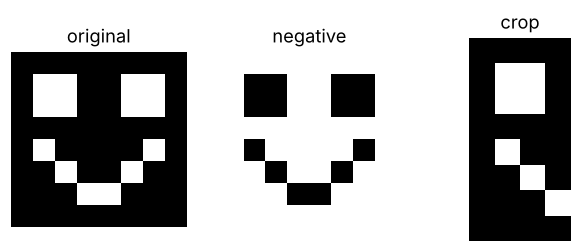

shape: (8, 8) - lit pixels: 14


In [12]:
image = np.array([
    [  0,   0,   0,   0,   0,   0,   0,   0],
    [  0, 255, 255,   0,   0, 255, 255,   0],
    [  0, 255, 255,   0,   0, 255, 255,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0],
    [  0, 255,   0,   0,   0,   0, 255,   0],
    [  0,   0, 255,   0,   0, 255,   0,   0],
    [  0,   0,   0, 255, 255,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0],
])
negative = 255 - image            # one operation on 64 pixels, no loop
left_half = image[:, :4]          # cropping with slicing

fig, axes = plt.subplots(1, 3, figsize=(7, 2.4))
for ax, img, title in zip(axes, [image, negative, left_half], ["original", "negative", "crop"]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()
print("shape:", image.shape, "- lit pixels:", (image > 0).sum())

## 5. Broadcasting

So far we combined an array with a scalar, or two arrays of the same shape. Broadcasting is the rule by which NumPy combines arrays of different shapes, virtually "stretching" the smaller one without copying data.

The rule: the two shapes are compared starting from the right. Two dimensions are compatible if they are equal or if one of them is 1; missing dimensions on the left count as 1. If a pair is not compatible, NumPy raises an error.

| Operation | Shapes | Result shape |
|---|---|---|
| matrix and scalar | `(3, 4)` and `()` | `(3, 4)` |
| matrix and row vector | `(3, 4)` and `(4,)` | `(3, 4)`: the vector is applied to every row |
| column and row | `(3, 1)` and `(1, 4)` | `(3, 4)`: all combinations |
| incompatible | `(3, 4)` and `(3,)` | error: 4 and 3 differ and neither is 1 |

In [13]:
X = np.array([[7, 8, 6, 9],
              [5, 6, 7, 6],
              [9, 9, 8, 10]])

subject_means = X.mean(axis=0)               # shape (4,)
print("deviation from each subject's mean:\n", X - subject_means)     # (3, 4) - (4,)

column = np.array([[0], [10], [20]])         # shape (3, 1)
row = np.array([1, 2, 3, 4])                 # shape (4,)
print("\ncolumn + row, shape", (column + row).shape, ":\n", column + row)

try:
    X - X.mean(axis=1)                       # (3, 4) - (3,): not compatible
except ValueError as error:
    print("\nValueError:", error)
print("With keepdims the collapsed dimension stays, with length 1:", X.mean(axis=1, keepdims=True).shape)

deviation from each subject's mean:
 [[ 0.          0.33333333 -1.          0.66666667]
 [-2.         -1.66666667  0.         -2.33333333]
 [ 2.          1.33333333  1.          1.66666667]]

column + row, shape (3, 4) :
 [[ 1  2  3  4]
 [11 12 13 14]
 [21 22 23 24]]

ValueError: operands could not be broadcast together with shapes (3,4) (3,) 
With keepdims the collapsed dimension stays, with length 1: (3, 1)


### The distance from one point to all the others

A query point `q` is given; `X` contains the coordinates of n points, one row per point. With lists, the Euclidean distance from each point is computed with a loop:

```python
def distances_with_loop(q, X):
    result = []
    for p in X:
        total = 0
        for j in range(len(q)):
            total += (p[j] - q[j]) ** 2
        result.append(total ** 0.5)
    return result
```

`distances_from(q, X)` returns an array of n distances, with no loops, and works with any number of columns. `X - q` is a broadcasting `(n, d) - (d,)`: `q` is treated as `(1, d)`, that is, as a row, and subtracted from every row of `X`. Then the squares are summed along the right axis and `np.sqrt` is applied.

This function is the heart of the algorithm built in Part B.

In [14]:
def distances_from(q, X):
    differences = X - q                              # (n, d) - (d,) -> every row minus q
    return np.sqrt((differences ** 2).sum(axis=1))   # sum over the features: from (n, d) to (n,)

In [15]:
points = np.array([[5, 7], [4, 8], [2, 3], [1, 4]])
d = distances_from(np.array([3, 3]), points)
assert d.shape == (4,)
assert np.allclose(d, [4.47213595, 5.09901951, 1.0, 2.23606798])
assert d.argmin() == 2                                          # the closest point is the one at index 2
assert np.allclose(distances_from(np.zeros(3), np.array([[1.0, 2.0, 2.0]])), [3.0])   # works in 3 dimensions too
print("Check passed: distances_from")

Check passed: distances_from


What changes: with a million points the code is identical. `d.argmin()` returns the position of the minimum value: it is the "closest point".

### Standardizing the columns

Standardizing a feature means subtracting its mean and dividing by its standard deviation: afterwards the column has mean 0 and standard deviation 1, whatever its unit of measurement was.

`standardize(X, mean, std)` takes two vectors with one value per column. It is a single line: the point is understanding why the shapes are compatible.

In [16]:
def standardize(X, mean, std):
    return (X - mean) / std          # (n, d) with (d,): mean and std are applied to every row

In [17]:
data = np.array([[170.0, 60000.0], [180.0, 30000.0], [160.0, 45000.0]])   # height in cm, income in euros
Z = standardize(data, data.mean(axis=0), data.std(axis=0))
assert Z.shape == data.shape
assert np.allclose(Z.mean(axis=0), 0) and np.allclose(Z.std(axis=0), 1)
print(Z.round(2))
print("Check passed: standardize")

[[ 0.    1.22]
 [ 1.22 -1.22]
 [-1.22  0.  ]]
Check passed: standardize


## 6. Three tools needed shortly

`np.argsort` returns not the sorted values but the indices that would sort them. An array of indices can be used to select elements of another array (fancy indexing). `np.unique` with `return_counts=True` counts how many times each value appears.

In [18]:
distances = np.array([4.5, 5.1, 1.0, 2.2])
labels = np.array(["B", "B", "A", "A"])

order = np.argsort(distances)
print("order (indices from closest to farthest):", order)
print("sorted distances:        ", distances[order])
print("labels in the same order:", labels[order])
print("labels of the 3 closest: ", labels[order[:3]])

values, counts = np.unique(labels[order[:3]], return_counts=True)
print("values:", values, "- counts:", counts, "- position of the maximum count:", counts.argmax())

order (indices from closest to farthest): [2 3 0 1]
sorted distances:         [1.  2.2 4.5 5.1]
labels in the same order: ['A' 'A' 'B' 'B']
labels of the 3 closest:  ['A' 'A' 'B']
values: ['A' 'B'] - counts: [2 1] - position of the maximum count: 0


### The majority vote

`majority_vote(labels)` returns the most frequent label in an array. In case of a tie it returns the smallest value (alphabetically first for strings): this is what comes naturally from `np.unique`, which returns the values sorted, and `argmax`, which in case of a tie returns the first position.

In [19]:
def majority_vote(labels):
    values, counts = np.unique(labels, return_counts=True)
    return values[counts.argmax()]

In [20]:
assert majority_vote(np.array(["A", "A", "B"])) == "A"
assert majority_vote(np.array([1, 0, 1, 1, 2])) == 1
assert majority_vote(np.array(["B", "A"])) == "A"        # tie: the smallest label wins
assert majority_vote(np.array([7])) == 7
print("Check passed: majority_vote")

Check passed: majority_vote


Recap of Part A.

| | Python list | NumPy array |
|---|---|---|
| Element type | any, even mixed | one only, fixed (`dtype`) |
| Size | grows and shrinks (`append`, `pop`) | fixed at creation |
| Memory | pointers plus one object per element | contiguous block, data only |
| Arithmetic | `+` concatenates, `*` repeats | `+`, `*`, `-` act element by element |
| Slicing | creates a copy | creates a view |
| Operations on all elements | loop or comprehension | vectorized, with broadcasting |

It is not a contest: lists remain the tool for heterogeneous data and sequences that change length. NumPy comes in when the data are numbers, there are many of them, and operations on all of them at once are needed. That is the case of machine learning.

# Part B – A first model: k-Nearest Neighbors

## 7. Learning from examples

In traditional programming we write the rules ourselves. In supervised learning we give the program already-solved examples and ask it to answer on new cases.

The examples are a training set of n pairs: a matrix `X` of shape `(n, d)` with the features and a vector `y` of n labels, one per example. Given a new point `q`, we want to predict its label. If the labels are classes (spam or not spam, the digit from 0 to 9) the problem is called classification.

k-Nearest Neighbors (kNN) is the simplest algorithm to state:

1. compute the distance between `q` and all the examples in the training set;
2. select the k closest examples;
3. count their labels;
4. answer with the class that received the most votes.

In formulas, if $N_k(\mathbf{q})$ is the set of indices of the k examples closest to $\mathbf{q}$:

$$
\hat{y}(\mathbf{q}) = \underset{c}{\arg\max} \sum_{i \in N_k(\mathbf{q})} \mathbb{1}[y_i = c]
\qquad\text{with}\qquad
\delta(\mathbf{q}, \mathbf{x}_i) = \sqrt{\sum_{j=1}^{d} (q_j - x_{ij})^2}
$$

where $\mathbb{1}[\cdot]$ is 1 if the condition is true and 0 otherwise.

Two observations before writing code.

The assumption everything rests on is that nearby points have the same label. The distance is not an implementation detail: it is the entire bet the algorithm makes. If the distance does not capture the similarity that matters for the problem, no choice of k will save the model.

kNN has no real training phase: it memorizes the data and postpones all the work to prediction time. For this reason it is called lazy, or instance-based. Almost every other model does the opposite: it studies the data once, extracts a few parameters from them, and then forgets them.

The three functions needed were already written in Part A: `distances_from`, `np.argsort`, `majority_vote`.

## 8. A worked example: nine points in the plane

Nine points, two classes. Class A forms a cluster at the bottom left; class B a cluster at the top right, plus an isolated example, $P_5 = (3.5,\ 3.5)$, sitting in between. It could be a labeling error or a rare but legitimate case: kNN does not know, and cannot know.

| Point | $x_1$ | $x_2$ | Class |
|:-----:|:-----:|:-----:|:------:|
| $P_1$ | 2 | 2 | A |
| $P_2$ | 2 | 3 | A |
| $P_3$ | 3 | 2 | A |
| $P_4$ | 1 | 2 | A |
| $P_5$ | 3.5 | 3.5 | B |
| $P_6$ | 5 | 6 | B |
| $P_7$ | 6 | 5 | B |
| $P_8$ | 6 | 6 | B |
| $P_9$ | 7 | 7 | B |

Working it out by hand first makes the role of k concrete: classify the query $\mathbf{q} = (3, 3)$ with k = 1, 3 and 5. To rank the points the squared distance is enough, the square root is not needed.

The calculation:

| Point | Computation of $\delta^2$ | $\delta^2$ | $\delta$ | Class |
|:-----:|:---------------------|:----:|:-----:|:---:|
| $P_5$ | $(3.5-3)^2 + (3.5-3)^2 = 0.25 + 0.25$ | 0.5 | 0.707 | B |
| $P_2$ | $(2-3)^2 + (3-3)^2 = 1 + 0$ | 1 | 1.000 | A |
| $P_3$ | $(3-3)^2 + (2-3)^2 = 0 + 1$ | 1 | 1.000 | A |
| $P_1$ | $(2-3)^2 + (2-3)^2 = 1 + 1$ | 2 | 1.414 | A |
| $P_4$ | $(1-3)^2 + (2-3)^2 = 4 + 1$ | 5 | 2.236 | A |
| $P_6$ | $(5-3)^2 + (6-3)^2 = 4 + 9$ | 13 | 3.606 | B |
| $P_7$ | $(6-3)^2 + (5-3)^2 = 9 + 4$ | 13 | 3.606 | B |
| $P_8$ | $(6-3)^2 + (6-3)^2 = 9 + 9$ | 18 | 4.243 | B |
| $P_9$ | $(7-3)^2 + (7-3)^2 = 16 + 16$ | 32 | 5.657 | B |

- k = 1: neighbors $\{P_5\}$, votes B = 1. Answer B.
- k = 3: neighbors $\{P_5, P_2, P_3\}$, votes A = 2, B = 1. Answer A.
- k = 5: neighbors $\{P_5, P_2, P_3, P_1, P_4\}$, votes A = 4, B = 1. Answer A.

The same point changes class as k varies. $P_2$ and $P_3$ are at the same distance: here it causes no trouble because they have the same class.

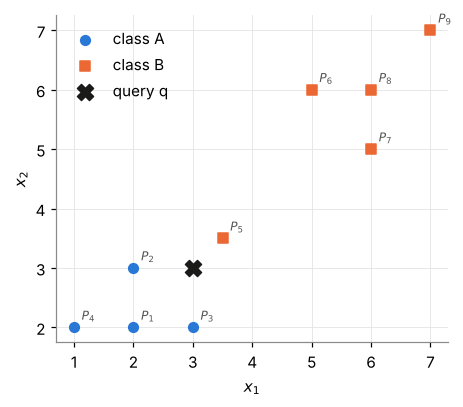

In [21]:
P = np.array([[2, 2], [2, 3], [3, 2], [1, 2],
              [3.5, 3.5], [5, 6], [6, 5], [6, 6], [7, 7]], dtype=float)
labels_P = np.array(["A", "A", "A", "A", "B", "B", "B", "B", "B"])
q = np.array([3.0, 3.0])


def plot_points(ax, X, y, q=None, names=False):
    # Plotting helper: first class as blue circles, second class as orange squares
    classes = np.unique(y)
    for cls, color, marker in zip(classes, (C_A, C_B), ("o", "s")):
        m = y == cls                                     # boolean mask of the examples of this class
        ax.scatter(X[m, 0], X[m, 1], s=40, marker=marker, color=color, label=f"class {cls}", zorder=3)
    if names:
        for i, (x1, x2) in enumerate(X):
            ax.annotate(f"$P_{{{i + 1}}}$", (x1, x2), (5, 5), textcoords="offset points", fontsize=8, color="#555")
    if q is not None:
        ax.scatter(*q, s=110, marker="X", color=C_Q, label="query q", zorder=4)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")


fig, ax = plt.subplots(figsize=(4.6, 4.2))
plot_points(ax, P, labels_P, q, names=True)
ax.set_aspect("equal")
ax.legend(loc="upper left")
plt.show()

### kNN for a single query

`knn_predict_one(q, X, y, k)` returns the predicted class for the point `q`, using `distances_from`, `np.argsort` and `majority_vote`. It is three lines: distances, indices of the k closest, vote.

The sort uses `np.argsort(..., kind="stable")`: with a stable algorithm, among points at equal distance the one that appears first in the training set stays first, and the result is reproducible.

In [22]:
def knn_predict_one(q, X, y, k):
    distances = distances_from(q, X)                        # (n,)
    neighbors = np.argsort(distances, kind="stable")[:k]    # indices of the k closest examples
    return majority_vote(y[neighbors])                      # fancy indexing on the labels, then vote

In [23]:
assert knn_predict_one(q, P, labels_P, 1) == "B"
assert knn_predict_one(q, P, labels_P, 3) == "A"
assert knn_predict_one(q, P, labels_P, 5) == "A"
assert knn_predict_one(q, P, labels_P, 9) == "B"
assert knn_predict_one(np.array([6.5, 6.5]), P, labels_P, 3) == "B"
print("Check passed: knn_predict_one\n")

for k in (1, 2, 3, 5, 9):
    print(f"k = {k}: predicted class {knn_predict_one(q, P, labels_P, k)}")

Check passed: knn_predict_one

k = 1: predicted class B
k = 2: predicted class A
k = 3: predicted class A
k = 5: predicted class A
k = 9: predicted class B


The figure shows, for each k, the circle centered at `q` with radius equal to the distance of the k-th neighbor: the points inside the circle or on its border are the ones that vote.

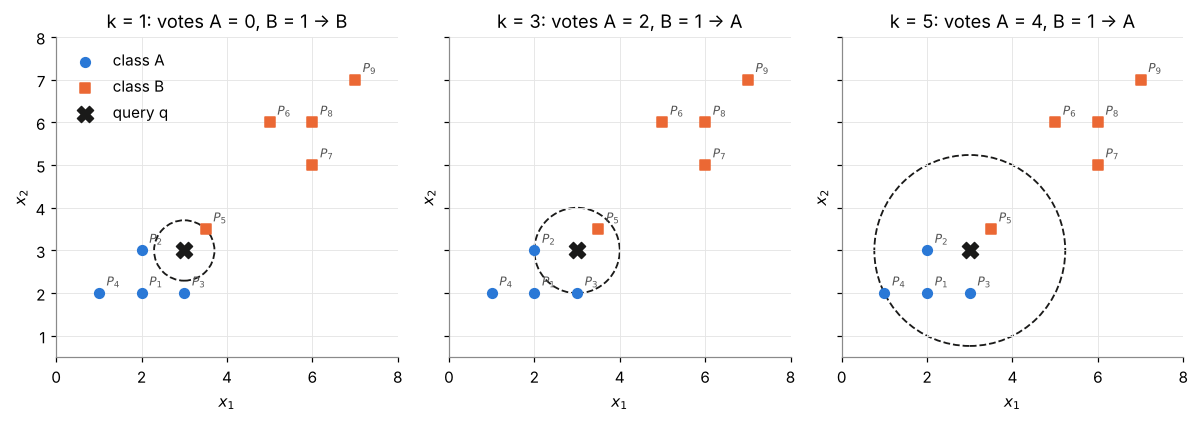

In [24]:
distances_q = distances_from(q, P)
order_q = np.argsort(distances_q, kind="stable")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, k in zip(axes, (1, 3, 5)):
    plot_points(ax, P, labels_P, q, names=True)
    radius = distances_q[order_q[k - 1]]
    ax.add_patch(plt.Circle(q, radius, fill=False, color=C_Q, linewidth=1.2, linestyle="--"))
    voters = labels_P[order_q[:k]]
    ax.set_title(f"k = {k}: votes A = {(voters == 'A').sum()}, B = {(voters == 'B').sum()} → {knn_predict_one(q, P, labels_P, k)}")
    ax.set_xlim(0, 8)
    ax.set_ylim(0.5, 8)
    ax.set_aspect("equal")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

Reading the result. The same point changes class as k varies.

- With k = 1 the prediction depends on a single example, the isolated neighbor $P_5$, and follows it blindly: if $P_5$ is a wrong label, the prediction is wrong.
- With k = 3 and k = 5 the collective vote of cluster A absorbs the anomaly.
- With k = 2 the votes are 1 to 1: a tie. Our rule (the smallest label wins) answers A, but it is a convention, not a reason. This is why with two classes an odd k is chosen.
- With k = 9, that is all the points, B wins 5 votes to 4 wherever the query is: the model always answers with the most numerous class and ignores position entirely.

Small k: the model chases every single example, wrong ones included. Large k: the model ignores the local structure. This trade-off is measured in section 10.

## 9. From one query to many: the distance matrix

Evaluating a model takes hundreds of predictions. Calling `knn_predict_one` in a loop works, but we can do better: compute in one go the distances between all m queries and all n examples, in a matrix `D` of shape `(m, n)` where `D[i, j]` is the distance between query i and example j.

The tool is again broadcasting, this time in three dimensions. Indexing with `None` inserts a dimension of length 1:

- `A[:, None, :]` has shape `(m, 1, d)`
- `B[None, :, :]` has shape `(1, n, d)`
- their difference has shape `(m, n, d)`: for every (query, example) pair, the d differences over the features.

Summing the squares along the last axis, the feature dimension disappears and the `(m, n)` matrix remains.

In [25]:
A = np.array([[0.0, 0.0], [3.0, 4.0]])                  # 2 queries in 2 dimensions
B = np.array([[0.0, 1.0], [1.0, 0.0], [3.0, 0.0]])      # 3 examples

print("A[:, None, :].shape =", A[:, None, :].shape)
print("B[None, :, :].shape =", B[None, :, :].shape)
differences = A[:, None, :] - B[None, :, :]
print("differences.shape   =", differences.shape, " (m, n, d)")

A[:, None, :].shape = (2, 1, 2)
B[None, :, :].shape = (1, 3, 2)
differences.shape   = (2, 3, 2)  (m, n, d)


### The distance matrix

`distance_matrix(A, B)` returns the `(m, n)` matrix of Euclidean distances between the rows of `A` and the rows of `B`, with no loops.

In [26]:
def distance_matrix(A, B):
    differences = A[:, None, :] - B[None, :, :]          # (m, 1, d) - (1, n, d) -> (m, n, d)
    return np.sqrt((differences ** 2).sum(axis=2))       # (m, n)

In [27]:
D = distance_matrix(A, B)
assert D.shape == (2, 3)
assert np.allclose(D, [[1.0, 1.0, 3.0], [4.24264069, 4.47213595, 4.0]])
assert np.allclose(distance_matrix(q[None, :], P)[0], distances_from(q, P))    # one row = the distances of one query
print(D.round(3))
print("Check passed: distance_matrix")

[[1.    1.    3.   ]
 [4.243 4.472 4.   ]]
Check passed: distance_matrix


### The `KNN` class

Let's package everything in a class with the same interface as every scikit-learn model: `fit(X, y)` to train, `predict(X)` to predict. The `fit` method does nothing but store the data.

`predict(X)` receives a matrix of m queries and returns an array of m predicted classes:

1. the distance matrix between the queries and the training set;
2. for each row, the indices of the k closest examples: `np.argsort` accepts `axis=1` (and `kind="stable"`), then the first k columns are kept;
3. the labels of the neighbors: `self.y[indices]` with `indices` of shape `(m, k)` returns an `(m, k)` matrix of labels;
4. the vote, row by row.

In [28]:
class KNN:
    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        # kNN learns no parameters: it stores the training set
        self.X = np.asarray(X, dtype=float)
        self.y = np.asarray(y)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        D = distance_matrix(X, self.X)                                  # (m, n)
        neighbors = np.argsort(D, axis=1, kind="stable")[:, :self.k]    # (m, k): indices of the k closest
        labels = self.y[neighbors]                                      # (m, k): their labels
        return np.array([majority_vote(row) for row in labels])

In [29]:
queries = np.array([[3.0, 3.0], [6.5, 6.5], [1.0, 1.0]])
for k in (1, 3, 5):
    model = KNN(k=k).fit(P, labels_P)
    predicted = model.predict(queries)
    expected = np.array([knn_predict_one(x, P, labels_P, k) for x in queries])
    assert predicted.shape == (3,)
    assert (predicted == expected).all()
assert (KNN(k=3).fit(P, labels_P).predict(queries) == ["A", "B", "A"]).all()
print("Check passed: KNN")

Check passed: KNN


A Python loop over the rows remains in the vote: it is short (one iteration per query, not one per pair) and keeps the code readable. The heavy work, the m × n distances, is all inside NumPy.

How much is gained? Let's compare our class with the classic textbook version, found in many tutorials, which computes one distance at a time with two nested loops.

In [30]:
def knn_with_loops(X_train, y_train, X_query, k):
    # "One point at a time" version: a loop over the queries and one over the examples
    predicted = []
    for x in X_query:
        distances = [np.sqrt(np.sum((x - x_train) ** 2)) for x_train in X_train]
        neighbors = np.argsort(distances, kind="stable")[:k]
        predicted.append(majority_vote(y_train[neighbors]))
    return np.array(predicted)


rng = np.random.default_rng(0)
X_big, y_big = rng.random((2000, 4)), rng.integers(0, 3, 2000)    # 2000 examples, 4 features, 3 classes
X_query = rng.random((200, 4))                                    # 200 queries

model = KNN(k=3).fit(X_big, y_big)
t_loops = benchmark(knn_with_loops, X_big, y_big, X_query, 3, repetitions=2)     # in milliseconds
t_numpy = benchmark(model.predict, X_query, repetitions=2)

print(f"two nested loops: {t_loops:8.1f} ms")
print(f"vectorized:       {t_numpy:8.1f} ms   -> {t_loops / t_numpy:.0f}x faster")
print("same predictions:", (knn_with_loops(X_big, y_big, X_query, 3) == model.predict(X_query)).all())

two nested loops:    946.6 ms
vectorized:           30.5 ms   -> 31x faster


same predictions: True


Moving from `distances_from` (one point against all) to `distance_matrix` (all against all) has a cost: the intermediate tensor of differences holds `m × n × d` numbers. With 200 queries, 2000 examples and 4 features that is 1.6 million numbers, about 13 MB: no problem. With large data the queries are processed in blocks. Keep this in mind: it comes back in section 12.

## 10. How good is the model? Training set, validation set, test set

Let's move to a more realistic dataset: 400 points in two crescent-shaped classes, with noise. The two classes overlap: no model can classify all of them correctly.

X: (400, 2) - y: (400,) - classes: [0 1]


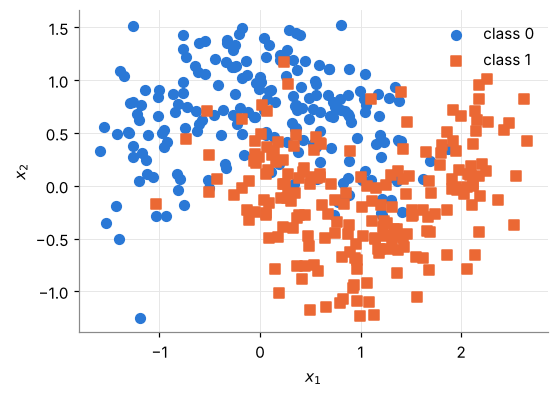

In [31]:
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(n_samples=400, noise=0.35, random_state=42)
print("X:", X_moons.shape, "- y:", y_moons.shape, "- classes:", np.unique(y_moons))

fig, ax = plt.subplots(figsize=(5.5, 3.8))
plot_points(ax, X_moons, y_moons)
ax.legend(loc="upper right")
plt.show()

First attempt at evaluation: train the model on all the points and measure the accuracy on the same points.

In [32]:
for k in (1, 15):
    model = KNN(k=k).fit(X_moons, y_moons)
    print(f"k = {k:2d}: accuracy on the same data used for training = {accuracy(model.predict(X_moons), y_moons):.3f}")

k =  1: accuracy on the same data used for training = 1.000
k = 15: accuracy on the same data used for training = 0.877


With k = 1 the accuracy is 100%. That is not good news: every point is its own nearest neighbor, so the model is simply reading back the answer we gave it. It is like testing a student on the very exercises, solutions included, that they were given to study from.

What we care about is how the model behaves on data it has never seen: its ability to generalize. To measure it, a portion of the data must be set aside before training. There are three portions, each with a job.

| Portion | Typical share | What it is for |
|---|:--:|---|
| Training set | 60% | Training the model (for kNN: the examples to store) |
| Validation set | 20% | Comparing alternatives and choosing, for instance, the value of k |
| Test set | 20% | Estimating once, at the end, the quality of the chosen model |

Why two separate sets for choosing and for evaluating? If we choose k by looking at the test set, the chosen value is the one that happens to work best on exactly those points, and the accuracy we report is optimistic. The test set is used once, when every decision has already been made.

### Splitting the data

`split_train_test(X, y, test_fraction, seed)` shuffles the examples and returns `X_train, X_test, y_train, y_test`. Steps:

1. a random generator with the given seed: `np.random.default_rng(seed)`;
2. a permutation of the indices from 0 to n-1: `rng.permutation(n)`;
3. the first `n_test` indices go to the test set, the others to the training set, with `n_test = round(n * test_fraction)`;
4. the same index selection is applied to `X` and to `y`, otherwise the labels no longer match the examples.

In [33]:
def split_train_test(X, y, test_fraction=0.25, seed=0):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(X))                    # the indices 0..n-1 in random order
    n_test = round(len(X) * test_fraction)
    test, train = indices[:n_test], indices[n_test:]
    return X[train], X[test], y[train], y[test]

In [34]:
X_check = np.arange(100, dtype=float).reshape(100, 1)     # example i has feature i ...
y_check = np.arange(100)                                  # ... and label i
Xa, Xb, ya, yb = split_train_test(X_check, y_check, test_fraction=0.25, seed=0)
assert Xa.shape == (75, 1) and Xb.shape == (25, 1) and ya.shape == (75,) and yb.shape == (25,)
assert (Xa[:, 0] == ya).all() and (Xb[:, 0] == yb).all()            # examples and labels stay aligned
assert sorted(np.concatenate([ya, yb])) == list(range(100))         # no example lost or duplicated
assert not (ya == np.arange(75)).all()                              # the data have been shuffled
assert (split_train_test(X_check, y_check, 0.25, seed=0)[3] == yb).all()   # same seed, same split
print("Check passed: split_train_test")

Check passed: split_train_test


The split is applied twice: first 20% is set aside for the test, then a quarter of the rest (that is, 20% of the total) for validation.

training: (240, 2) - validation: (80, 2) - test: (80, 2)


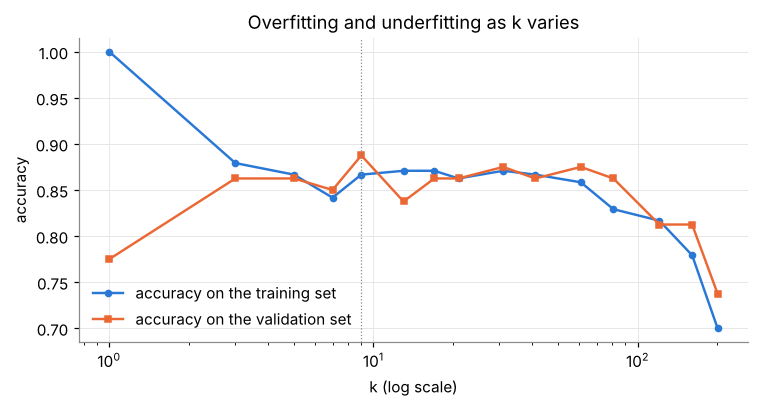

best k on the validation set: 9  (accuracy 0.887)
with k = 1:   training 1.000, validation 0.775
with k = 201: training 0.700, validation 0.738


In [35]:
X_rest, X_test, y_rest, y_test = split_train_test(X_moons, y_moons, test_fraction=0.20, seed=0)
X_train, X_val, y_train, y_val = split_train_test(X_rest, y_rest, test_fraction=0.25, seed=1)
print("training:", X_train.shape, "- validation:", X_val.shape, "- test:", X_test.shape)

k_values = [1, 3, 5, 7, 9, 13, 17, 21, 31, 41, 61, 81, 121, 161, 201]
acc_train, acc_val = [], []
for k in k_values:
    model = KNN(k=k).fit(X_train, y_train)
    acc_train.append(accuracy(model.predict(X_train), y_train))
    acc_val.append(accuracy(model.predict(X_val), y_val))

best_k = k_values[int(np.argmax(acc_val))]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(k_values, acc_train, marker="o", ms=4, lw=1.6, color=C_A, label="accuracy on the training set")
ax.plot(k_values, acc_val, marker="s", ms=4, lw=1.6, color=C_B, label="accuracy on the validation set")
ax.axvline(best_k, color="#888", lw=0.8, ls=":")
ax.set_xscale("log")
ax.set_xlabel("k (log scale)")
ax.set_ylabel("accuracy")
ax.set_title("Overfitting and underfitting as k varies")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

print(f"best k on the validation set: {best_k}  (accuracy {max(acc_val):.3f})")
print(f"with k = 1:   training {acc_train[0]:.3f}, validation {acc_val[0]:.3f}")
print(f"with k = 201: training {acc_train[-1]:.3f}, validation {acc_val[-1]:.3f}")

This is the most important figure of the notebook, and the same picture comes back with every model.

- On the left, small k: perfect accuracy on the training set, much lower on the validation set. The model has memorized the data, noise included, and generalizes poorly. This is called overfitting, or high variance: changing a few examples would be enough to change the predictions.
- On the right, large k: the two curves go down together. The model is too rigid to capture the shape of the data. This is called underfitting, or high bias.
- In between is the useful zone. The validation curve there is almost flat and irregular: with 80 validation examples each error is worth 1.25 percentage points, so the "best k" is the maximum of a noisy curve, not a precise value. When several values are equivalent the smallest is preferable: more local and cheaper predictions. Try a different seed in `split_train_test`: the best k changes, which makes the noisiness of the curve concrete.

The signal to recognize is the gap between the two curves: when the accuracy on the training set is much higher than on validation, the model is overfitting.

Decision regions make the same thing visible: apply the model to every point of the plane and color it by the predicted class.

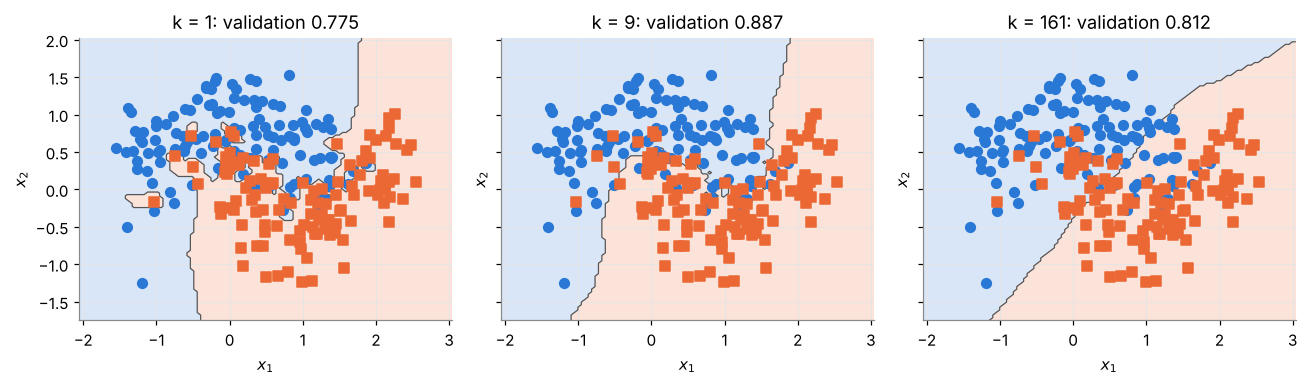

In [36]:
def plot_decision_regions(ax, model, X, y, steps=110):
    # Plotting helper: colors the plane by the class predicted by the model
    x1 = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, steps)
    x2 = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, steps)
    xx, yy = np.meshgrid(x1, x2)
    grid = np.c_[xx.ravel(), yy.ravel()]                          # all the grid points, one per row
    Z = (model.predict(grid) == np.unique(y)[1]).astype(int).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=[C_A, C_B], alpha=0.18)
    ax.contour(xx, yy, Z, levels=[0.5], colors="#555", linewidths=0.8)
    plot_points(ax, X, y)


fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, k in zip(axes, (1, best_k, 161)):
    model = KNN(k=k).fit(X_train, y_train)
    plot_decision_regions(ax, model, X_train, y_train)
    ax.set_title(f"k = {k}: validation {accuracy(model.predict(X_val), y_val):.3f}")
plt.tight_layout()
plt.show()

With k = 1 every isolated point carves out its own island. With a very large k the boundary is almost a straight line and the crescent shape is lost.

Now that k is chosen, and only now, we open the test set.

In [37]:
final_model = KNN(k=best_k).fit(X_train, y_train)
acc_test = accuracy(final_model.predict(X_test), y_test)
print(f"k = {best_k}: accuracy on the test set = {acc_test:.3f}")
print(f"for comparison, k = 1 on the test set: {accuracy(KNN(k=1).fit(X_train, y_train).predict(X_test), y_test):.3f}")

k = 9: accuracy on the test set = 0.900
for comparison, k = 1 on the test set: 0.863


This number too must be read with caution: the test set has 80 examples, and a different split would give a slightly different value. Cross-validation, which repeats the split several times and averages the results precisely to reduce this uncertainty, is the subject of a later notebook.

## 11. The scale of the features

The Euclidean distance sums the squared differences over all the features. If one feature has values numerically much larger than the others, it dominates the sum and the others stop counting: not because they are less informative, but by an accident of units.

Experiment: suppose the first feature is a length in meters and re-express it in millimeters. The data are the same, only the unit has changed.

In [38]:
unit_change = np.array([1000.0, 1.0])            # first feature from meters to millimeters, second unchanged
X_train_mm, X_val_mm = X_train * unit_change, X_val * unit_change

model = KNN(k=best_k).fit(X_train, y_train)
print(f"original units:                 validation {accuracy(model.predict(X_val), y_val):.3f}")

model = KNN(k=best_k).fit(X_train_mm, y_train)
print(f"first feature in millimeters:   validation {accuracy(model.predict(X_val_mm), y_val):.3f}")

mean, std = X_train_mm.mean(axis=0), X_train_mm.std(axis=0)      # computed ONLY on the training set
model = KNN(k=best_k).fit(standardize(X_train_mm, mean, std), y_train)
print(f"in millimeters, standardized:   validation {accuracy(model.predict(standardize(X_val_mm, mean, std)), y_val):.3f}")

original units:                 validation 0.887
first feature in millimeters:   validation 0.700
in millimeters, standardized:   validation 0.863


With the first feature in millimeters the model effectively looks at that feature only, and the accuracy collapses. The standardization of section 5 puts the features back on the same footing and brings the accuracy close to the starting value: the remaining difference corresponds to two examples out of 80, within the noise of such a small validation set.

A detail that is a principle: mean and standard deviation are computed on the training set only, and then applied as they are to validation and test. If we computed them on all the data, information about the evaluation data would enter the construction of the model. This contamination is called data leakage: here the effect would be minimal, but it is the most frequent and most insidious methodological error.

The practical rule is "with kNN, standardize", because the features almost always have different units. It should be treated as a hypothesis to verify on the validation set, though, not as a reflex: if the features are already in the same unit, standardizing can even make things worse.

## 12. A real problem: recognizing handwritten digits

The dataset contains 1797 handwritten digits, digitized as 8 × 8 grayscale images with values from 0 (white) to 16 (black). Each image is already "unrolled" into a row of 64 numbers: the data matrix has shape `(1797, 64)`. For kNN a digit is a point in a 64-dimensional space.

X: (1797, 64) - y: (1797,) - classes: [0 1 2 3 4 5 6 7 8 9]
the first row, reshaped to 8 x 8:
 [[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]


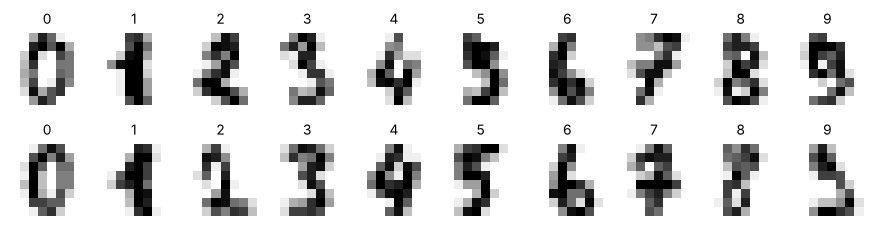

In [39]:
from sklearn.datasets import load_digits

digits = load_digits()
X_digits, y_digits = digits.data, digits.target
print("X:", X_digits.shape, "- y:", y_digits.shape, "- classes:", np.unique(y_digits))
print("the first row, reshaped to 8 x 8:\n", X_digits[0].reshape(8, 8).astype(int))

fig, axes = plt.subplots(2, 10, figsize=(10, 2.4))
for ax, digit_image, label in zip(axes.ravel(), X_digits, y_digits):
    ax.imshow(digit_image.reshape(8, 8), cmap="gray_r")      # reshape: from 64 numbers to an 8 x 8 matrix
    ax.set_title(label, fontsize=9)
    ax.axis("off")
plt.show()

Same procedure as before: three portions, choice of k on the validation set, test at the end. We use the `KNN` class of section 9 without changing a line: the algorithm does not know what the 64 columns represent.

No standardization here: the 64 pixels are already all in the same unit, from 0 to 16.

In [40]:
Xd_rest, Xd_test, yd_rest, yd_test = split_train_test(X_digits, y_digits, test_fraction=0.20, seed=0)
Xd_train, Xd_val, yd_train, yd_val = split_train_test(Xd_rest, yd_rest, test_fraction=0.25, seed=1)
print("training:", Xd_train.shape, "- validation:", Xd_val.shape, "- test:", Xd_test.shape)

m, n, d = len(Xd_val), len(Xd_train), Xd_train.shape[1]
print(f"tensor of differences: {m} x {n} x {d} = {m * n * d:,} numbers, about {m * n * d * 8 / 1e6:.0f} MB\n")

results = {}
for k in (1, 3, 5, 7, 9, 11):
    results[k] = accuracy(KNN(k=k).fit(Xd_train, yd_train).predict(Xd_val), yd_val)
    print(f"k = {k:2d}: validation accuracy {results[k]:.4f}")

k_digits = max(results, key=results.get)      # the k with the highest accuracy (the smallest, in case of a tie)
print("\nchosen k:", k_digits)

training: (1078, 64) - validation: (360, 64) - test: (359, 64)
tensor of differences: 360 x 1078 x 64 = 24,837,120 numbers, about 199 MB



k =  1: validation accuracy 0.9833
k =  3: validation accuracy 0.9889


k =  5: validation accuracy 0.9889
k =  7: validation accuracy 0.9806


k =  9: validation accuracy 0.9778
k = 11: validation accuracy 0.9694

chosen k: 3


In [41]:
digits_model = KNN(k=k_digits).fit(Xd_train, yd_train)
test_predictions = digits_model.predict(Xd_test)
print(f"accuracy on the test set: {accuracy(test_predictions, yd_test):.4f}"
      f"   ({(test_predictions != yd_test).sum()} errors out of {len(yd_test)} digits)")

accuracy on the test set: 0.9889   (4 errors out of 359 digits)


With about twenty lines of NumPy, written by hand, and no training, the model recognizes almost all the digits correctly. Let's look at the ones it gets wrong, and for the first one also at why: kNN has a property many models lack: every prediction can be explained by showing the neighbors that voted.

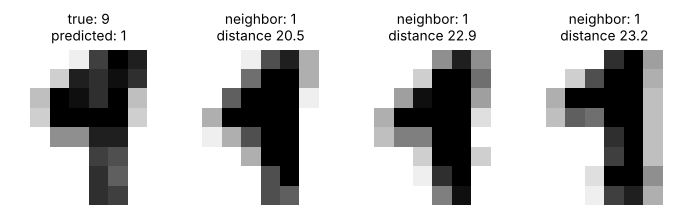

All the errors (true -> predicted): 9 -> 1, 8 -> 3, 8 -> 1, 8 -> 2


In [42]:
wrong = np.flatnonzero(test_predictions != yd_test)         # indices of the misclassified test digits

if len(wrong) == 0:
    print("No errors on the test set.")
else:
    i = wrong[0]
    D_i = distance_matrix(Xd_test[[i]], Xd_train)[0]
    neighbors = np.argsort(D_i, kind="stable")[:k_digits]

    fig, axes = plt.subplots(1, k_digits + 1, figsize=(1.6 * (k_digits + 1), 2.0))
    axes[0].imshow(Xd_test[i].reshape(8, 8), cmap="gray_r")
    axes[0].set_title(f"true: {yd_test[i]}\npredicted: {test_predictions[i]}", fontsize=9)
    for ax, j in zip(axes[1:], neighbors):
        ax.imshow(Xd_train[j].reshape(8, 8), cmap="gray_r")
        ax.set_title(f"neighbor: {yd_train[j]}\ndistance {D_i[j]:.1f}", fontsize=9)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    print("All the errors (true -> predicted):",
          ", ".join(f"{yd_test[j]} -> {test_predictions[j]}" for j in wrong))

### Comparison with scikit-learn

scikit-learn has its own kNN, `KNeighborsClassifier`, with the same `fit` and `predict` interface. With `algorithm="brute"` it does exactly what we wrote: all the distances, then the k smallest.

In [43]:
from sklearn.neighbors import KNeighborsClassifier

ours = KNN(k=k_digits).fit(Xd_train, yd_train)
sklearn_model = KNeighborsClassifier(n_neighbors=k_digits, algorithm="brute").fit(Xd_train, yd_train)
pred_ours, pred_sklearn = ours.predict(Xd_test), sklearn_model.predict(Xd_test)
t_ours = benchmark(ours.predict, Xd_test, repetitions=3)
t_sklearn = benchmark(sklearn_model.predict, Xd_test, repetitions=3)

print(f"our KNN:      accuracy {accuracy(pred_ours, yd_test):.4f}   ({t_ours:6.1f} ms)")
print(f"scikit-learn: accuracy {accuracy(pred_sklearn, yd_test):.4f}   ({t_sklearn:6.1f} ms)")
print(f"matching predictions: {(pred_ours == pred_sklearn).mean():.1%}")

our KNN:      accuracy 0.9889   ( 166.1 ms)
scikit-learn: accuracy 0.9889   (   1.8 ms)
matching predictions: 100.0%


The predictions coincide: inside the library is the same algorithm. The library is faster because it does not build the `m × n × d` tensor. It uses an algebraic identity:

$$
\|\mathbf{a} - \mathbf{b}\|^2 = \|\mathbf{a}\|^2 + \|\mathbf{b}\|^2 - 2\,\mathbf{a}\cdot\mathbf{b}
$$

The dot products between all the queries and all the examples are a single matrix product, `A @ B.T`, which NumPy runs with highly optimized routines. The next cell shows that the same distance matrix is obtained without the intermediate tensor; this is what scikit-learn's `euclidean_distances` does. The identity has a numerical weakness: for two nearly identical points the subtraction cancels almost everything and the result can lose precision, which is why `np.maximum(D2, 0)` is needed and why the library falls back to a slower, more stable computation when it matters. Matrix multiplication is also the core operation of neural networks: a network is a sequence of operations like this one.

In [44]:
def distance_matrix_fast(A, B):
    squares_A = (A ** 2).sum(axis=1)[:, None]                  # (m, 1)
    squares_B = (B ** 2).sum(axis=1)[None, :]                  # (1, n)
    D2 = squares_A + squares_B - 2 * A @ B.T                   # (m, n), by broadcasting
    return np.sqrt(np.maximum(D2, 0))                          # maximum: rounding can give -0.0000001


t_tensor = benchmark(distance_matrix, Xd_test, Xd_train, repetitions=3)
t_matmul = benchmark(distance_matrix_fast, Xd_test, Xd_train, repetitions=3)
print(f"with the (m, n, d) tensor:   {t_tensor:7.1f} ms")
print(f"with the matrix product:     {t_matmul:7.1f} ms   -> {t_tensor / t_matmul:.0f}x faster")
print("same result:", np.allclose(distance_matrix(Xd_test, Xd_train), distance_matrix_fast(Xd_test, Xd_train)))

with the (m, n, d) tensor:     139.2 ms
with the matrix product:         2.2 ms   -> 63x faster
same result: True


## 13. Where kNN falls short

The cost moves to prediction. `fit` is free, but every query must be compared with all the stored examples, and the model to keep is the whole training set. With a million examples and a hundred features a single prediction costs a hundred million operations. A parametric model, such as linear regression or a neural network, pays during training and then answers in a time that does not depend on how many examples it has seen.

Irrelevant features weigh as much as useful ones. Every column enters the distance with the same weight: kNN has no mechanism to figure out which features matter.

In many dimensions, closeness loses meaning. This is the deepest and least intuitive limit, and it is called the curse of dimensionality. Let's measure it: 1000 random points in a hypercube, and the ratio between the distance of the farthest and that of the closest from a random query.

In [45]:
rng = np.random.default_rng(0)
print("dimensions   max distance / min distance")
for d in (2, 10, 100, 1000):
    random_points, random_query = rng.random((1000, d)), rng.random(d)
    distances = distances_from(random_query, random_points)
    print(f"{d:10d}   {distances.max() / distances.min():8.2f}")

dimensions   max distance / min distance
         2     135.62
        10       4.48
       100       1.39
      1000       1.11


In 2 dimensions the farthest point is more than a hundred times farther than the closest; in 1000 dimensions it is only about a tenth farther. If all the points are at almost the same distance, "the k closest" are no more special than the others.

Why, then, did it work so well with the digits, in 64 dimensions? Because real data do not fill space at random: images of digits occupy a small, structured region of pixel space, and there the distance still has meaning. On photographs of objects, where shifting the subject by one pixel changes every value, the distance between pixels no longer measures similarity, and kNN on raw pixels does not work.

This does not make it a museum piece. Nearest-neighbor search is the heart of the vector databases with which systems based on language models retrieve the documents relevant to a question. The difference is that the vectors are not raw data: they are produced by a neural network, trained precisely so that the distance between two vectors matches similarity of meaning. kNN stays; what is learned is the representation.

## 14. Summary

The NumPy tools used in this notebook, and where.

| Tool | What it was used for |
|---|---|
| Vectorized operations | Normalizing, computing errors, replacing loops |
| Boolean masks | Accuracy, filters, selecting the examples of a class |
| `axis` | Summing over the features to get one distance per example |
| Broadcasting | One point against all, then all against all |
| `argsort` and fancy indexing | Selecting the k neighbors and their labels |
| `np.unique` with counts | The majority vote |
| `rng.permutation` | Splitting the data into training, validation and test |
| `reshape` | Going from a row of 64 numbers to an 8 × 8 image |

The machine learning ideas, which come back with every model.

| Idea | In one line |
|---|---|
| Supervised learning | Examples `X` with labels `y`; the goal is to predict well on new data |
| Generalization | What counts is the error on unseen data, not on the training data |
| Overfitting and underfitting | Model too flexible or too rigid: the training vs validation comparison reveals it |
| Hyperparameter | A choice the model does not learn by itself (here k), fixed on the validation set |
| Test set | Used once, after all decisions are made |
| Feature scale and data leakage | Transformations are computed on the training set and applied to the others |

kNN has a peculiarity: it learns nothing, it memorizes. The model is the dataset. The natural next step is the first model that really learns: a few numbers, the parameters, that summarize the data, and an algorithm that finds them by correcting them one step at a time in the direction that reduces the error. That is gradient descent, the same algorithm used to train neural networks.

### Sources

- A. Géron, *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*: the `tools_numpy` notebook (arrays, broadcasting, vectorization) and chapter 3 (classification on handwritten digits; `KNeighborsClassifier` in the exercises).
- A. Ng, *Machine Learning Specialization* (DeepLearning.AI): labs on vectorization and broadcasting, and on the split into training, cross-validation and test sets.
- E. Fix, J. Hodges, *Discriminatory Analysis. Nonparametric Discrimination: Consistency Properties*, 1951; T. Cover, P. Hart, *Nearest Neighbor Pattern Classification*, 1967.
- K. Beyer, J. Goldstein, R. Ramakrishnan, U. Shaft, *When Is "Nearest Neighbor" Meaningful?*, 1999 (the curse of dimensionality experiment of section 13).
- scikit-learn: `metrics.pairwise.euclidean_distances` (the matrix-product identity of section 12); datasets `make_moons` and `load_digits`, the latter from the UCI *Optical Recognition of Handwritten Digits* dataset (E. Alpaydin, C. Kaynak, 1998).